# Smart Retail Analytics & Demand Forecasting

## 01 — Exploratory Data Analysis (EDA)

### Project Objective
This project aims to analyze historical retail sales data,
identify sales patterns, and develop machine learning models
to forecast future product demand.

### Dataset
Store Sales — Time Series Forecasting (Kaggle)

### EDA Objectives
- Understand the dataset structure
- Identify missing values and duplicates
- Analyze sales distributions
- Explore sales trends over time
- Investigate store and product family patterns

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [18]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Files:", [file.name for file in DATA_DIR.iterdir()])

Project directory: C:\Users\MR.Co\Desktop\Smart_Retail_Analytics
Data directory: C:\Users\MR.Co\Desktop\Smart_Retail_Analytics\data\raw
Files: ['holidays_events.csv', 'stores.csv', 'train.csv']


In [19]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["date"])
stores = pd.read_csv(DATA_DIR / "stores.csv")
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv", parse_dates=["date"])

print("Train shape:", train.shape)
print("Stores shape:", stores.shape)
print("Holidays shape:", holidays.shape)

Train shape: (3000888, 6)
Stores shape: (54, 5)
Holidays shape: (350, 6)


In [20]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [21]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


In [22]:
train.describe()

,id,date,store_nbr,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088384,2.750000e+01,3.577757e+02,2.602770e+00
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01


In [23]:
missing_values = train.isnull().sum()

missing_values

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [24]:
duplicates = train.duplicated().sum()

print("Number of duplicated rows:", duplicates)

Number of duplicated rows: 0


In [25]:
daily_sales = (
    train.groupby("date")["sales"].sum().reset_index()
)

daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


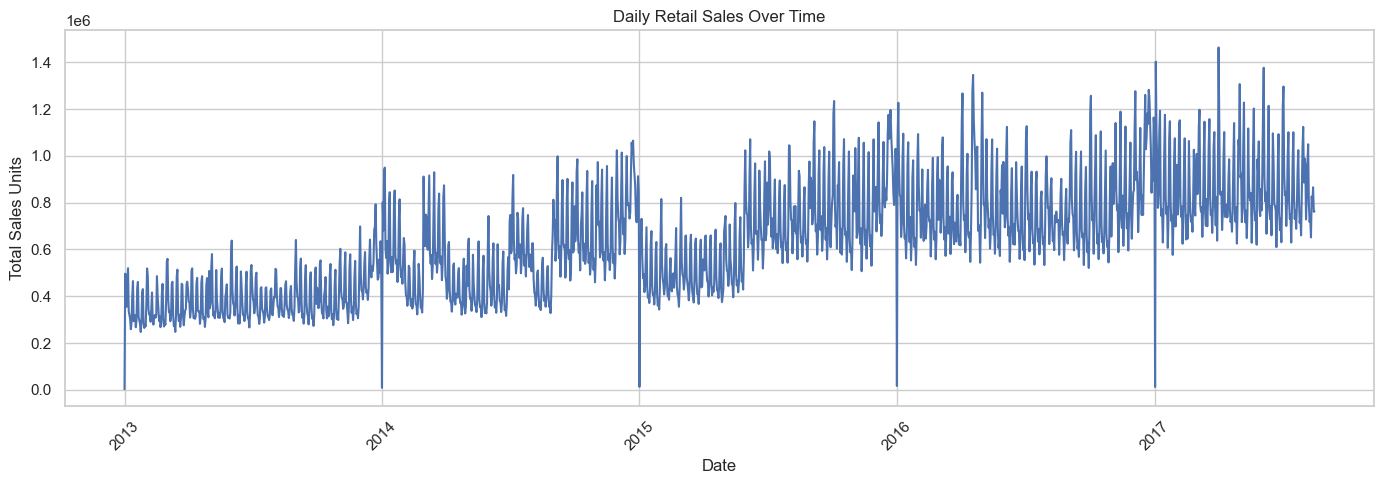

In [26]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales Units")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
duplicate_keys = train.duplicated(
    subset=["date", "store_nbr", "family"]
).sum()

print("Duplicate date-store-family:", duplicate_keys)

Duplicate date-store-family: 0


## Sales Distribution Analysis

In this section, we examine the distribution of sales values,
identify zero-sales observations, and investigate skewness.

In [28]:
# Calculate zero-sales percentage
zero_sales_pct = (train["sales"] == 0).mean() * 100

# Calculate skewness
sales_skewness = train["sales"].skew()

print(f"Zero sales: {zero_sales_pct:.2f}%")
print(f"Sales skewness: {sales_skewness:.2f}")

Zero sales: 31.30%
Sales skewness: 7.36


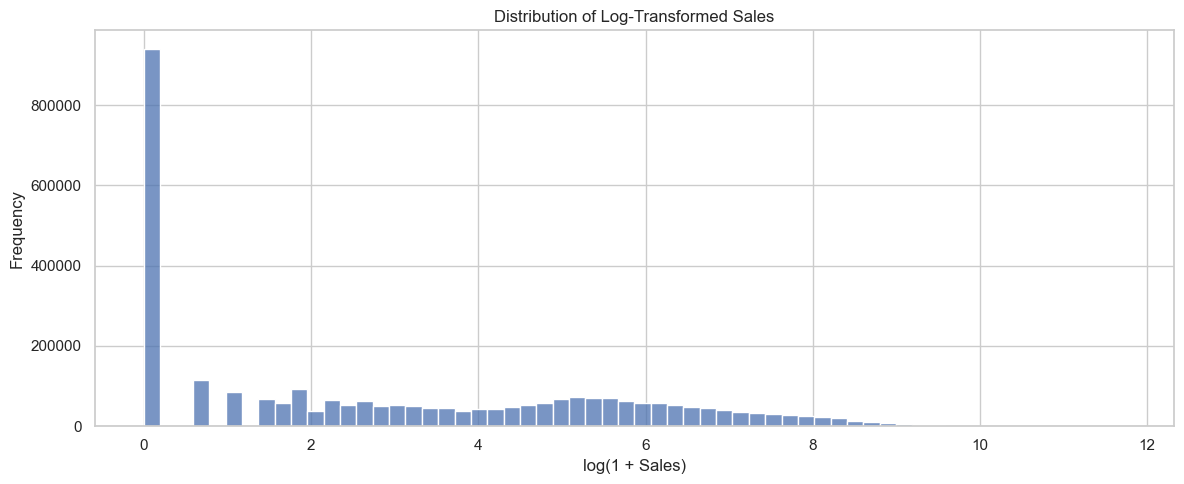

In [29]:
plt.figure(figsize=(12, 5))

sns.histplot(
    np.log1p(train["sales"]),
    bins=60
)

plt.title("Distribution of Log-Transformed Sales")
plt.xlabel("log(1 + Sales)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Sales Distribution — Key Findings

- Approximately 31.30% of sales observations are zero.
- The sales distribution is highly right-skewed, with a skewness value of 7.36.
- The mean sales value (357.78) is substantially higher than the median (11), indicating that a relatively small number of high-sales observations influence the average.
- Applying a `log1p` transformation makes the distribution easier to visualize while preserving zero-sales observations.
- These findings suggest that forecasting performance should be evaluated across different sales ranges and product families.

In [30]:
family_stats = (
    train.groupby("family")
    .agg(
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        zero_sales_pct=("sales", lambda x: (x == 0).mean() * 100)
    )
    .sort_values("mean_sales", ascending=False)
)

family_stats.head(10)

,mean_sales,median_sales,zero_sales_pct
family,,,
GROCERY I,3776.972100,3185.0000,8.062813
BEVERAGES,2385.793151,1784.0000,8.061714
PRODUCE,1349.352123,398.2905,28.355107
CLEANING,1072.416744,938.0000,8.061714
DAIRY,709.154889,520.0000,8.061714
BREAD/BAKERY,463.336254,401.0000,8.060614
POULTRY,350.532292,205.7430,8.076010
MEATS,341.849965,224.9365,8.061714
PERSONAL CARE,270.432513,222.0000,8.065013


## Zero-Sales Pattern Analysis

This section investigates whether zero-sales observations
are concentrated in specific stores or dates.

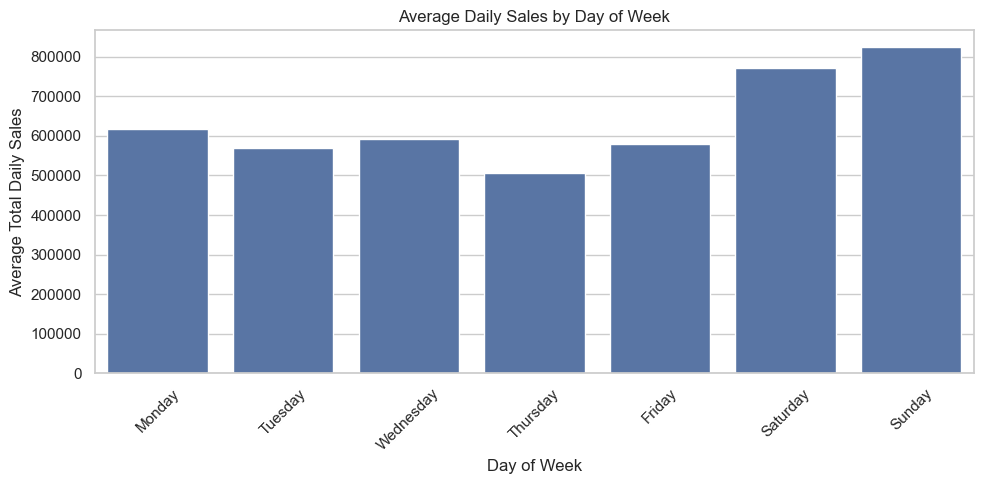

In [31]:
# Average daily sales by day of week
daily_sales["day_of_week"] = daily_sales["date"].dt.day_name()

weekly_pattern = (
    daily_sales.groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

plt.figure(figsize=(10, 5))
sns.barplot(x=weekly_pattern.index, y=weekly_pattern.values)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Total Daily Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Weekly Sales Pattern — Key Findings

- Average daily sales vary across the days of the week.
- Sunday has the highest average total sales, followed by Saturday.
- Thursday has the lowest average total sales.
- The observed weekly pattern suggests that day-of-week information may be useful for demand forecasting.

In [32]:
# Compare sales with and without promotions
train["has_promotion"] = train["onpromotion"] > 0

promotion_stats = (
    train.groupby("has_promotion")["sales"]
    .agg(["mean", "median"])
)

promotion_stats

,mean,median
has_promotion,,
False,158.246681,3.0
True,1137.693730,373.0


### Promotion Analysis — Key Findings

- Records with promotions have substantially higher average sales (1,137.69) than records without promotions (158.25).
- Median sales also differ considerably between the two groups (373 vs. 3).
- These results indicate a strong association between promotion status and recorded sales.
- However, this comparison does not establish a causal effect, as product families, stores, and time periods may influence the observed differences.
- The `onpromotion` variable will be considered as a potential predictor in the demand forecasting models.